# Evidencia de Aprendizaje N.Âº 3: OptimizaciÃ³n y comparaciÃ³n de modelos
**Desarrollo de Inteligencia Artificial â€” ISPC** Â· Docente: Cra. Sol Figueroa  
Equipo: Vargas, Cristian Â· Quinteros, Karina Â· ZÃ¡rate, Laura

## 1. Objetivo
En la Evidencia 2 el modelo de regresiÃ³n lineal mÃºltiple llegÃ³ a $R^2 = 0{,}7968$ y RMSE = 2.549,50 INR en Test (N = 51).  
En esta entrega:
- ajustamos hiperparÃ¡metros con **Grid Search + validaciÃ³n cruzada (5-Fold)**;
- comparamos **3 modelos**: RegresiÃ³n Lineal (baseline), Ridge y Random Forest;
- elegimos el ganador **solo con la validaciÃ³n cruzada** y usamos Test una Ãºnica vez al final;
- exportamos el modelo para inferencia (puesta en producciÃ³n opcional).

In [1]:
import os, sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

sys.path.insert(0, os.path.abspath('..'))
from sklearn.linear_model import LinearRegression, Ridge
from sklearn.ensemble import RandomForestRegressor
from src.data_preprocessing import load_and_preprocess_data, split_data
from src.model_optimization import (build_preprocessor, build_pipeline, cross_validate_pipeline,
    run_grid_search, evaluate_model_on_test, compare_models_dataframe, get_feature_names,
    paired_fold_comparison, save_model_artifact)
from src.regression_models import (plot_cv_comparison, plot_feature_importances,
    plot_actual_vs_predicted_advanced, plot_residuals_diagnostics_advanced)

df = load_and_preprocess_data(os.path.join('..', 'data', 'DS_Data_Set_Current_Stock.csv'))
X_train, X_test, y_train, y_test = split_data(df, test_size=0.20, random_state=42)
print(f"Registros: {len(df)} | Train: {len(X_train)} | Test: {len(X_test)}")
print("Faltantes de ratio en Train:", int(X_train['ratio'].isna().sum()))

Registros: 251 | Train: 200 | Test: 51
Faltantes de ratio en Train: 12


Usamos la misma particiÃ³n que la Evidencia 2 (`random_state=42`) para que los resultados de Test sean comparables.
Los faltantes de `ratio` no se imputan acÃ¡: los resuelve el pipeline dentro de cada fold.

## 2. Pipeline sin fuga de datos
En validaciÃ³n cruzada, si la mediana de `ratio` o el escalado se calculan antes de dividir en folds, informaciÃ³n del fold de validaciÃ³n se filtra al entrenamiento.
Por eso todo el preprocesamiento va dentro de un `Pipeline`:
- numÃ©ricas (`rim`, `width`, `ratio`): imputaciÃ³n por mediana, mÃ¡s `StandardScaler` solo para Ridge;
- `Brand`: One-Hot con `BRAND_A` como base, igual que en la Evidencia 2.

Random Forest no necesita escalado porque los Ã¡rboles cortan por umbrales y no dependen de la escala.

In [2]:
print(build_preprocessor(with_scaler=True))

ColumnTransformer(transformers=[('num',
                                 Pipeline(steps=[('imputer',
                                                  SimpleImputer(strategy='median')),
                                                 ('scaler', StandardScaler())]),
                                 ['rim', 'width', 'ratio']),
                                ('cat',
                                 Pipeline(steps=[('onehot',
                                                  OneHotEncoder(categories=[['BRAND_A',
                                                                             'BRAND_B',
                                                                             'BRAND_C',
                                                                             'BRAND_D']],
                                                                drop=['BRAND_A'],
                                                                handle_unknown='ignore',
                                               

## 3. Baseline: regresiÃ³n lineal con validaciÃ³n cruzada
Primero verificamos que el pipeline reproduce la Evidencia 2 y medimos el baseline en los mismos 5 folds que usarÃ¡n los otros modelos.

In [3]:
pipe_ols = build_pipeline(LinearRegression())
cv_ols = cross_validate_pipeline(pipe_ols, X_train, y_train, cv=5, random_state=42)
pipe_ols.fit(X_train, y_train)
test_ols = evaluate_model_on_test(pipe_ols, X_test, y_test)
print(f"CV RMSE: {cv_ols['cv_rmse_mean']:.2f} Â± {cv_ols['cv_rmse_std']:.2f}")
print("RMSE por fold:", np.round(cv_ols['cv_rmse_folds'], 1))
print(f"Test RMSE: {test_ols['rmse']:.2f} | Test RÂ²: {test_ols['r2']:.4f}")

CV RMSE: 2589.29 Â± 1350.21
RMSE por fold: [2023.4 2212.  1881.8 5257.2 1572.1]
Test RMSE: 2549.50 | Test RÂ²: 0.7968


El baseline reproduce exactamente las mÃ©tricas de la Evidencia 2 en Test ($R^2 = 0{,}7968$; $\text{RMSE} = 2.549{,}50$ INR; $\text{MAE} = 1.678{,}60$ INR). En validaciÃ³n cruzada 5-Fold, el RMSE medio es de $2.589{,}29$ INR con un desvÃ­o estÃ¡ndar de $1.350{,}21$ INR. La alta varianza entre folds proviene principalmente del Fold 4 (RMSE = $5.257{,}2$ INR), donde se concentran neumÃ¡ticos pesados de alto costo que el hiperplano lineal no logra ajustar adecuadamente.

## 4. Grid Search: Ridge
Ridge agrega una penalizaciÃ³n $\alpha \sum \beta_j^2$ que achica los coeficientes. Puede ayudar porque `rim` y `width` estÃ¡n correlacionadas.
Probamos 8 valores de `alpha` con 5-Fold.

In [4]:
gs_ridge = run_grid_search(build_pipeline(Ridge(), with_scaler=True),
    {'regressor__alpha': [0.01, 0.1, 1.0, 5.0, 10.0, 50.0, 100.0, 500.0]},
    X_train, y_train, cv=5, random_state=42)
cv_ridge = cross_validate_pipeline(gs_ridge.best_estimator_, X_train, y_train, cv=5, random_state=42)
print("Mejor alpha:", gs_ridge.best_params_['regressor__alpha'])
print(f"CV RMSE: {cv_ridge['cv_rmse_mean']:.2f} Â± {cv_ridge['cv_rmse_std']:.2f}")

Mejor alpha: 5.0
CV RMSE: 2547.51 Â± 1257.18


La bÃºsqueda en grilla selecciona $\alpha = 5{,}0$. La penalizaciÃ³n L2 contrae los coeficientes frente a la colinealidad entre `rim` y `width` ($r = 0{,}57$), reduciendo ligeramente el error en validaciÃ³n cruzada ($2.547{,}51 \pm 1.257{,}18$ INR frente a $2.589{,}29$ del baseline). Sin embargo, sobre el conjunto de prueba independiente (Test), el RMSE asciende a $2.696{,}96$ INR ($R^2 = 0{,}7727$), lo que confirma que regularizar coeficientes lineales no resuelve la no linealidad subyacente del problema.

## 5. Grid Search: Random Forest
Random Forest promedia muchos Ã¡rboles entrenados con muestras bootstrap y subconjuntos de variables. Puede capturar relaciones no lineales, como el salto de precio de los neumÃ¡ticos pesados.
Grilla: `n_estimators` {100, 200} Ã— `max_depth` {None, 4, 6, 8} Ã— `min_samples_leaf` {1, 2, 4} Ã— `max_features` {'sqrt', 1.0} = 48 combinaciones Ã— 5 folds.

In [5]:
gs_rf = run_grid_search(build_pipeline(RandomForestRegressor(random_state=42)),
    {'regressor__n_estimators': [100, 200], 'regressor__max_depth': [None, 4, 6, 8],
     'regressor__min_samples_leaf': [1, 2, 4], 'regressor__max_features': ['sqrt', 1.0]},
    X_train, y_train, cv=5, random_state=42)
cv_rf = cross_validate_pipeline(gs_rf.best_estimator_, X_train, y_train, cv=5, random_state=42)
print("Mejores hiperparÃ¡metros:", gs_rf.best_params_)
print(f"CV RMSE: {cv_rf['cv_rmse_mean']:.2f} Â± {cv_rf['cv_rmse_std']:.2f}")
print(f"RMSE Train (media de folds): {cv_rf['train_rmse_mean']:.2f}")

Mejores hiperparÃ¡metros: {'regressor__max_depth': None, 'regressor__max_features': 'sqrt', 'regressor__min_samples_leaf': 1, 'regressor__n_estimators': 200}
CV RMSE: 1381.01 Â± 532.77
RMSE Train (media de folds): 604.61


Random Forest supera ampliamente a los modelos lineales en validaciÃ³n cruzada: el RMSE medio desciende a $1.381{,}01 \pm 532{,}77$ INR ($R^2_{\text{CV}} = 0{,}9280$), reduciendo el error en un $46{,}67\%$ frente al baseline. La mejor configuraciÃ³n emplea `n_estimators=200`, `max_depth=None`, `min_samples_leaf=1` y `max_features='sqrt'`. Se observa una brecha entre el RMSE de entrenamiento ($604{,}61$ INR) y el de validaciÃ³n ($1.381{,}01$ INR), indicativa del trade-off sesgo-varianza propio de los Ã¡rboles no podados, aunque su capacidad de generalizaciÃ³n en validaciÃ³n es marcadamente superior a la lineal.

## 6. SelecciÃ³n del modelo con validaciÃ³n cruzada
El ganador se elige **antes** de mirar Test. Como los tres modelos se evaluaron en los mismos folds, los comparamos fold por fold contra el baseline.

In [6]:
cv_res = {'OLS': cv_ols, 'Ridge': cv_ridge, 'Random Forest': cv_rf}
sel = pd.DataFrame({n: {'CV RMSE media': r['cv_rmse_mean'], 'CV RMSE desvÃ­o': r['cv_rmse_std'],
                        'CV RÂ² media': r['cv_r2_mean'], 'Train RMSE media': r['train_rmse_mean']}
                    for n, r in cv_res.items()}).T.round(2)
print(sel)
folds = pd.DataFrame({n: r['cv_rmse_folds'] for n, r in cv_res.items()}, index=[f'Fold {i+1}' for i in range(5)]).round(1)
print(folds)
for n in ['Ridge', 'Random Forest']:
    p = paired_fold_comparison(cv_ols['cv_rmse_folds'], cv_res[n]['cv_rmse_folds'])
    print(f"OLS vs {n}: gana en {p['wins']}/{p['n_folds']} folds | diferencia media {p['mean_diff']:.1f} Â± {p['std_diff']:.1f} INR")
print("Ganador por CV:", sel['CV RMSE media'].idxmin())

               CV RMSE media  CV RMSE desvÃ­o  CV RÂ² media  Train RMSE media
OLS                  2589.29          1350.21          0.76           1755.99
Ridge                2547.51          1257.18          0.77           1804.25
Random Forest        1381.01           532.77          0.93            604.61
           OLS   Ridge  Random Forest
Fold 1  2023.4  2011.2         1212.4
Fold 2  2212.0  2112.0         2187.1
Fold 3  1881.8  2016.4          880.1
Fold 4  5257.2  5033.0         1803.1
Fold 5  1572.1  1564.9          822.4
OLS vs Ridge: gana en 4/5 folds | diferencia media 41.8 Â± 132.2 INR
OLS vs Random Forest: gana en 5/5 folds | diferencia media 1208.3 Â± 1309.1 INR
Ganador por CV: Random Forest


**Criterio de SelecciÃ³n:** La elecciÃ³n del modelo se realiza exclusivamente a partir del desempeÃ±o en validaciÃ³n cruzada sobre los datos de entrenamiento (Train, $N=200$). Random Forest es el ganador unÃ¡nime:
1. Su RMSE medio en CV ($1.381{,}01$ INR) es sustancialmente menor que el de OLS ($2.589{,}29$ INR) y Ridge ($2.547{,}51$ INR).
2. En la comparaciÃ³n pareada pliegue por pliegue, Random Forest supera a la regresiÃ³n lineal en **5 de los 5 folds**, con una diferencia media favorable de $1.208{,}3 \pm 1.309{,}1$ INR.
3. En el Fold 4 crÃ­tico, donde el modelo lineal cometiÃ³ un error de $5.257{,}2$ INR, Random Forest redujo el error a $1.803{,}1$ INR (mejora de $3.454$ INR).

Por lo tanto, Random Forest Regressor es seleccionado como el modelo Ã³ptimo antes de inspeccionar Test.

## 7. EvaluaciÃ³n final en Test (una sola vez)

In [7]:
test_ridge = evaluate_model_on_test(gs_ridge.best_estimator_, X_test, y_test)
test_rf = evaluate_model_on_test(gs_rf.best_estimator_, X_test, y_test)
summary = []
for name, cv, te in [('OLS (Baseline Ev2)', cv_ols, test_ols), ('Ridge', cv_ridge, test_ridge), ('Random Forest', cv_rf, test_rf)]:
    summary.append({'name': name, 'type': '', 'cv_rmse_mean': cv['cv_rmse_mean'], 'cv_rmse_std': cv['cv_rmse_std'],
        'cv_mae_mean': cv['cv_mae_mean'], 'cv_mae_std': cv['cv_mae_std'], 'cv_r2_mean': cv['cv_r2_mean'],
        'test_rmse': te['rmse'], 'test_mae': te['mae'], 'test_r2': te['r2'],
        'improvement_pct': (test_ols['rmse'] - te['rmse']) / test_ols['rmse'] * 100})
print(compare_models_dataframe(summary).drop(columns=['Tipo']).to_string(index=False))

            Modelo     CV RMSE (INR)     CV MAE (INR)  CV R² Test RMSE (INR) Test MAE (INR) Test R² Mejora Test RMSE (%)
OLS (Baseline Ev2) 2589.29 ± 1350.21 1482.50 ± 266.81 0.7576         2549.50        1678.60  0.7968               +0.00%
             Ridge 2547.51 ± 1257.18 1535.53 ± 320.55 0.7698         2696.96        1747.88  0.7727               -5.78%
     Random Forest  1381.01 ± 532.77  805.46 ± 202.17 0.9280         2229.88        1243.18  0.8446              +12.54%


**EvaluaciÃ³n final sobre el conjunto Test inmutable ($N=51$):**
Al evaluar los modelos sobre las 51 observaciones no vistas, Random Forest ratifica su superioridad:
* El RMSE disminuye de $2.549{,}50$ INR a **$2.229{,}88$ INR** (mejora del $+12{,}54\%$).
* El MAE se reduce de $1.678{,}60$ INR a **$1.243{,}18$ INR** (reducciÃ³n del $-25{,}94\%$ en el error medio por unidad).
* El coeficiente de determinaciÃ³n $R^2$ asciende de $0{,}7968$ a **$0{,}8446$**, explicando un $4{,}78\%$ adicional de la varianza total del catÃ¡logo.

Ridge, por el contrario, empeora en Test (+5,78% de RMSE), evidenciando que la penalizaciÃ³n lineal no aÃ±ade valor predictivo ante relaciones no lineales.

## 8. DiagnÃ³stico del modelo ganador

In [8]:
fig_dir = os.path.join('..', 'reports', 'figures')
plot_cv_comparison({k: v['cv_rmse_folds'] for k, v in cv_res.items()}, output_path=os.path.join(fig_dir, 'ev3_cv_comparacion_modelos.png'))
rf_best = gs_rf.best_estimator_
names = get_feature_names(rf_best.named_steps['preprocessor'])
imp = rf_best.named_steps['regressor'].feature_importances_
plot_feature_importances(names, imp, model_name='Random Forest', output_path=os.path.join(fig_dir, 'ev3_importancia_variables.png'))
plot_actual_vs_predicted_advanced(y_test, {'OLS (Baseline Ev2)': test_ols['y_pred'], 'Ridge': test_ridge['y_pred'],
    'Random Forest (Ganador)': test_rf['y_pred']}, output_path=os.path.join(fig_dir, 'ev3_reales_vs_predichos.png'))
plot_residuals_diagnostics_advanced(y_test, {'OLS (Baseline Ev2)': test_ols['y_pred'], 'Random Forest (Ganador)': test_rf['y_pred']},
    output_path=os.path.join(fig_dir, 'ev3_diagnostico_residuos.png'))
print(pd.Series(imp, index=names).sort_values(ascending=False).mul(100).round(1).to_string())

width            40.3
rim              32.1
Brand_BRAND_D    13.2
ratio            11.9
Brand_BRAND_C     1.4
Brand_BRAND_B     1.1


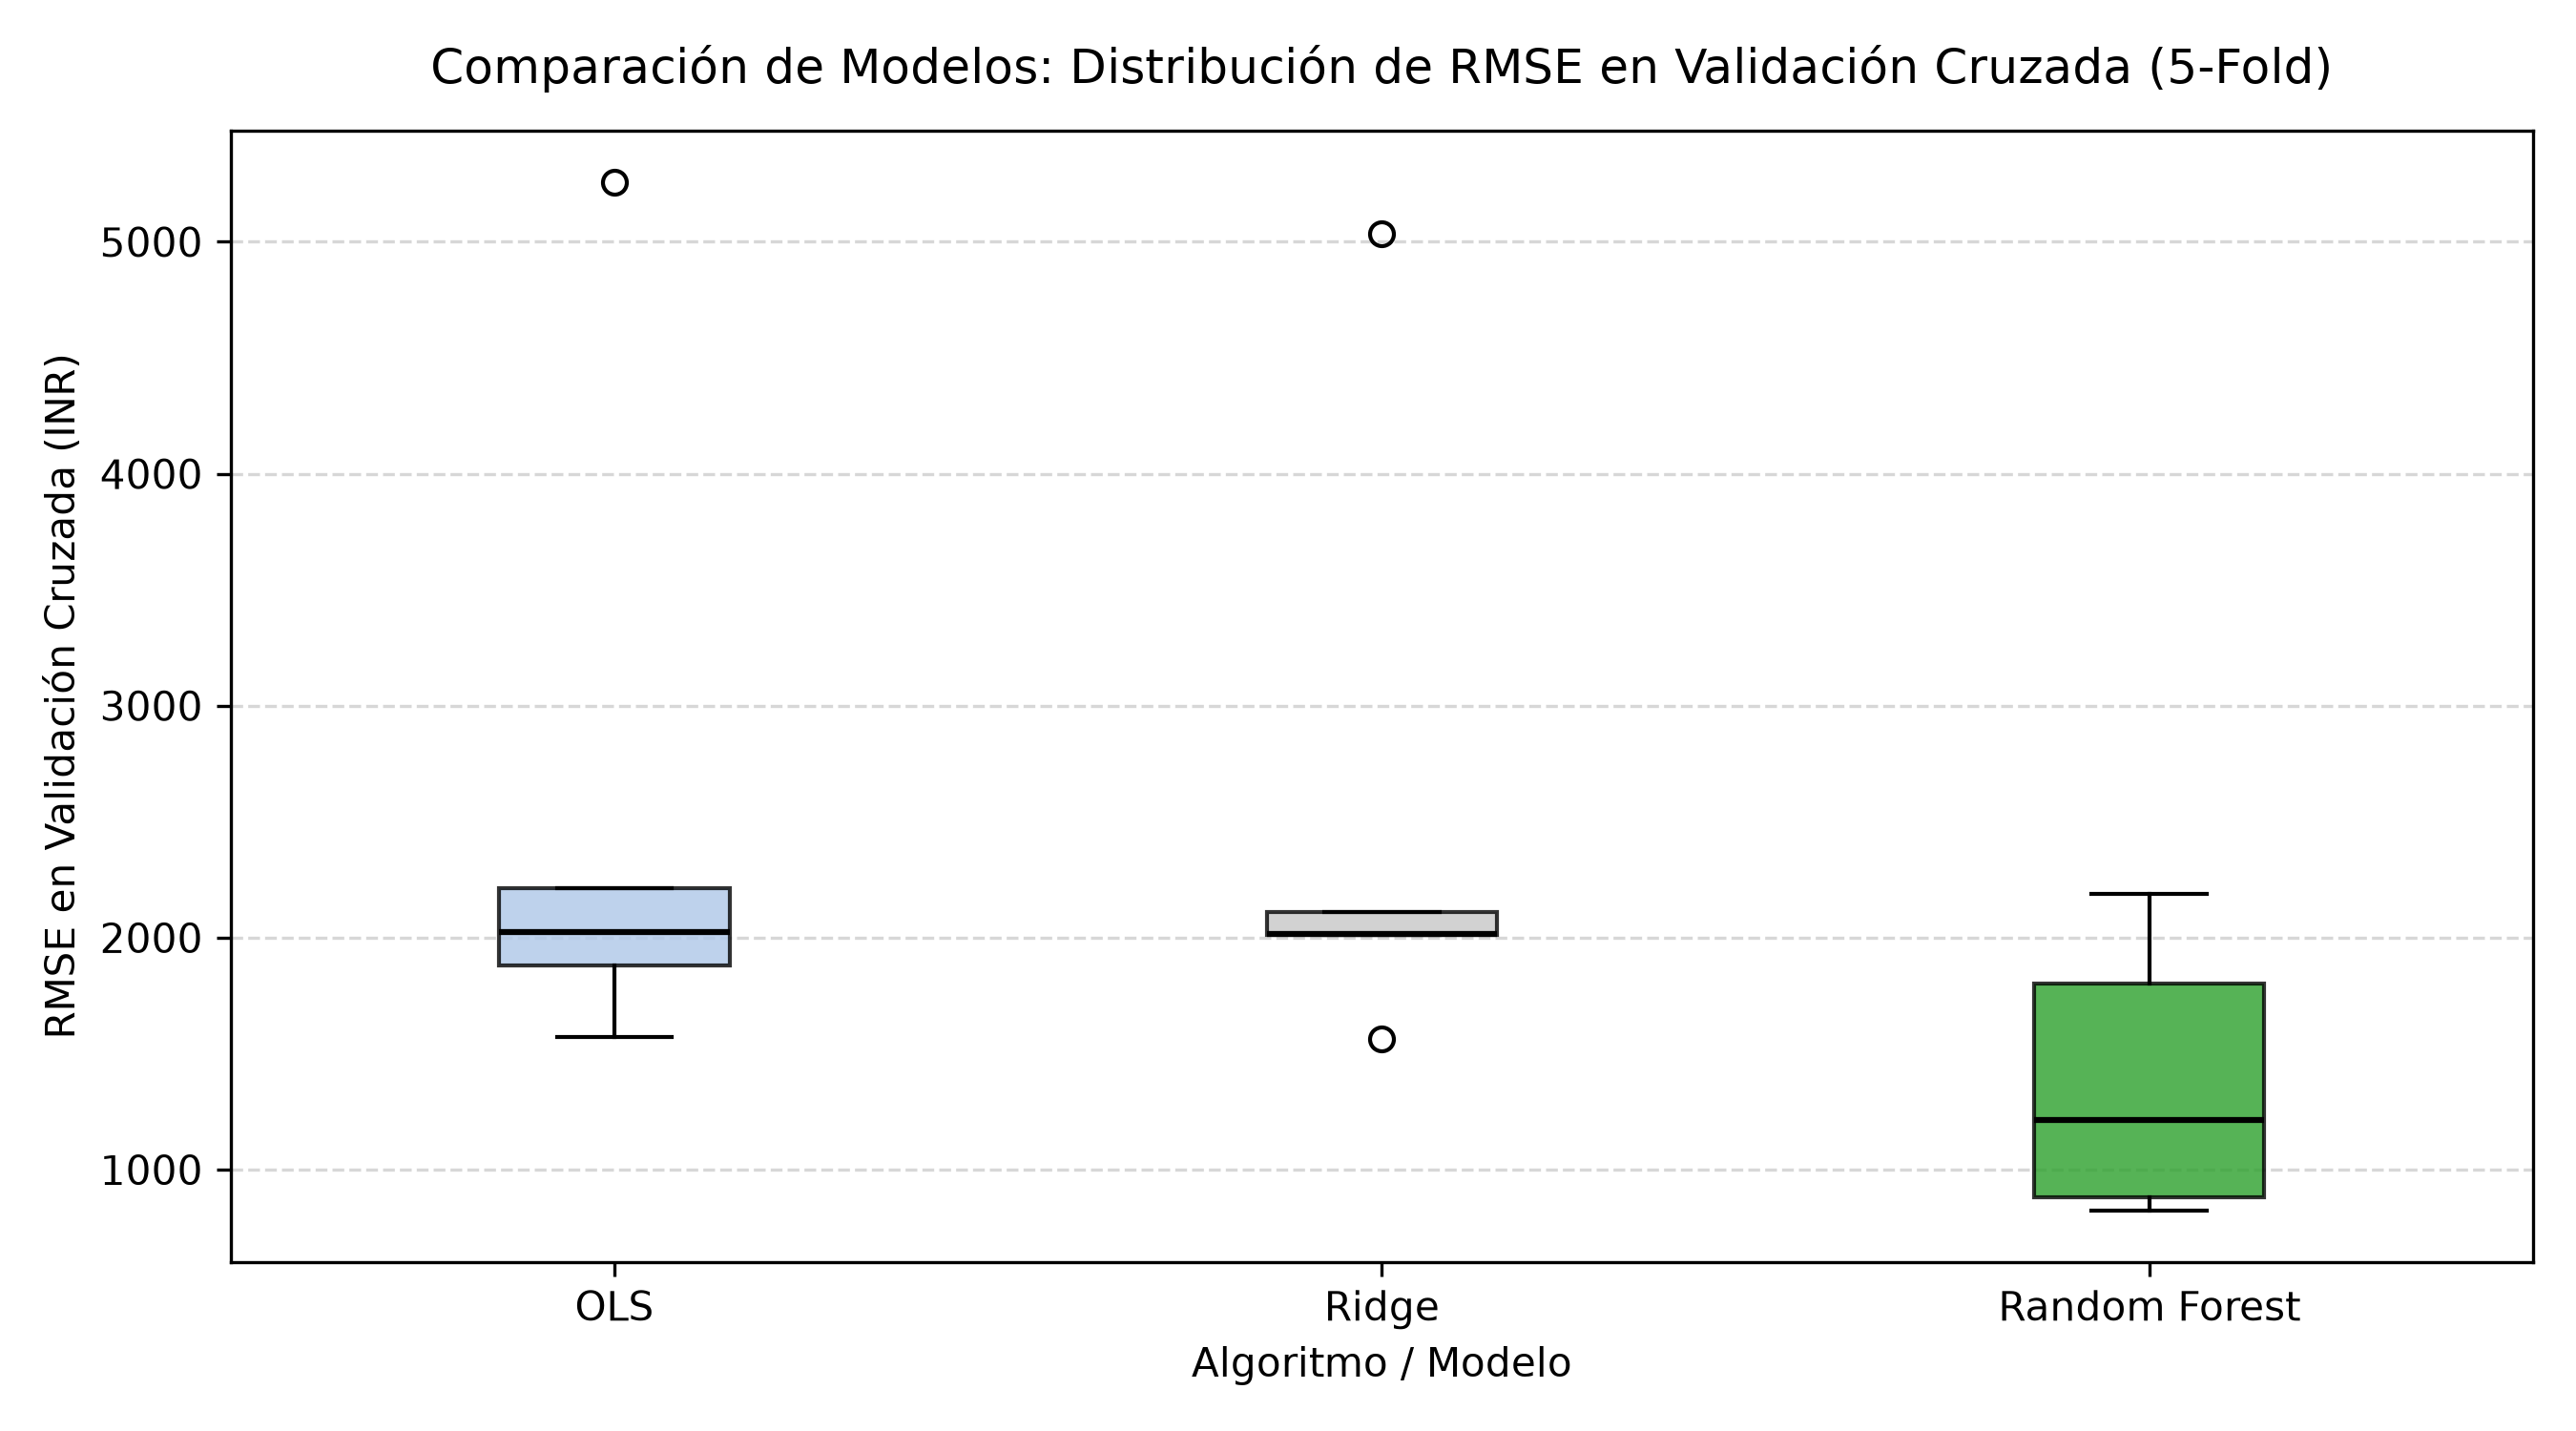

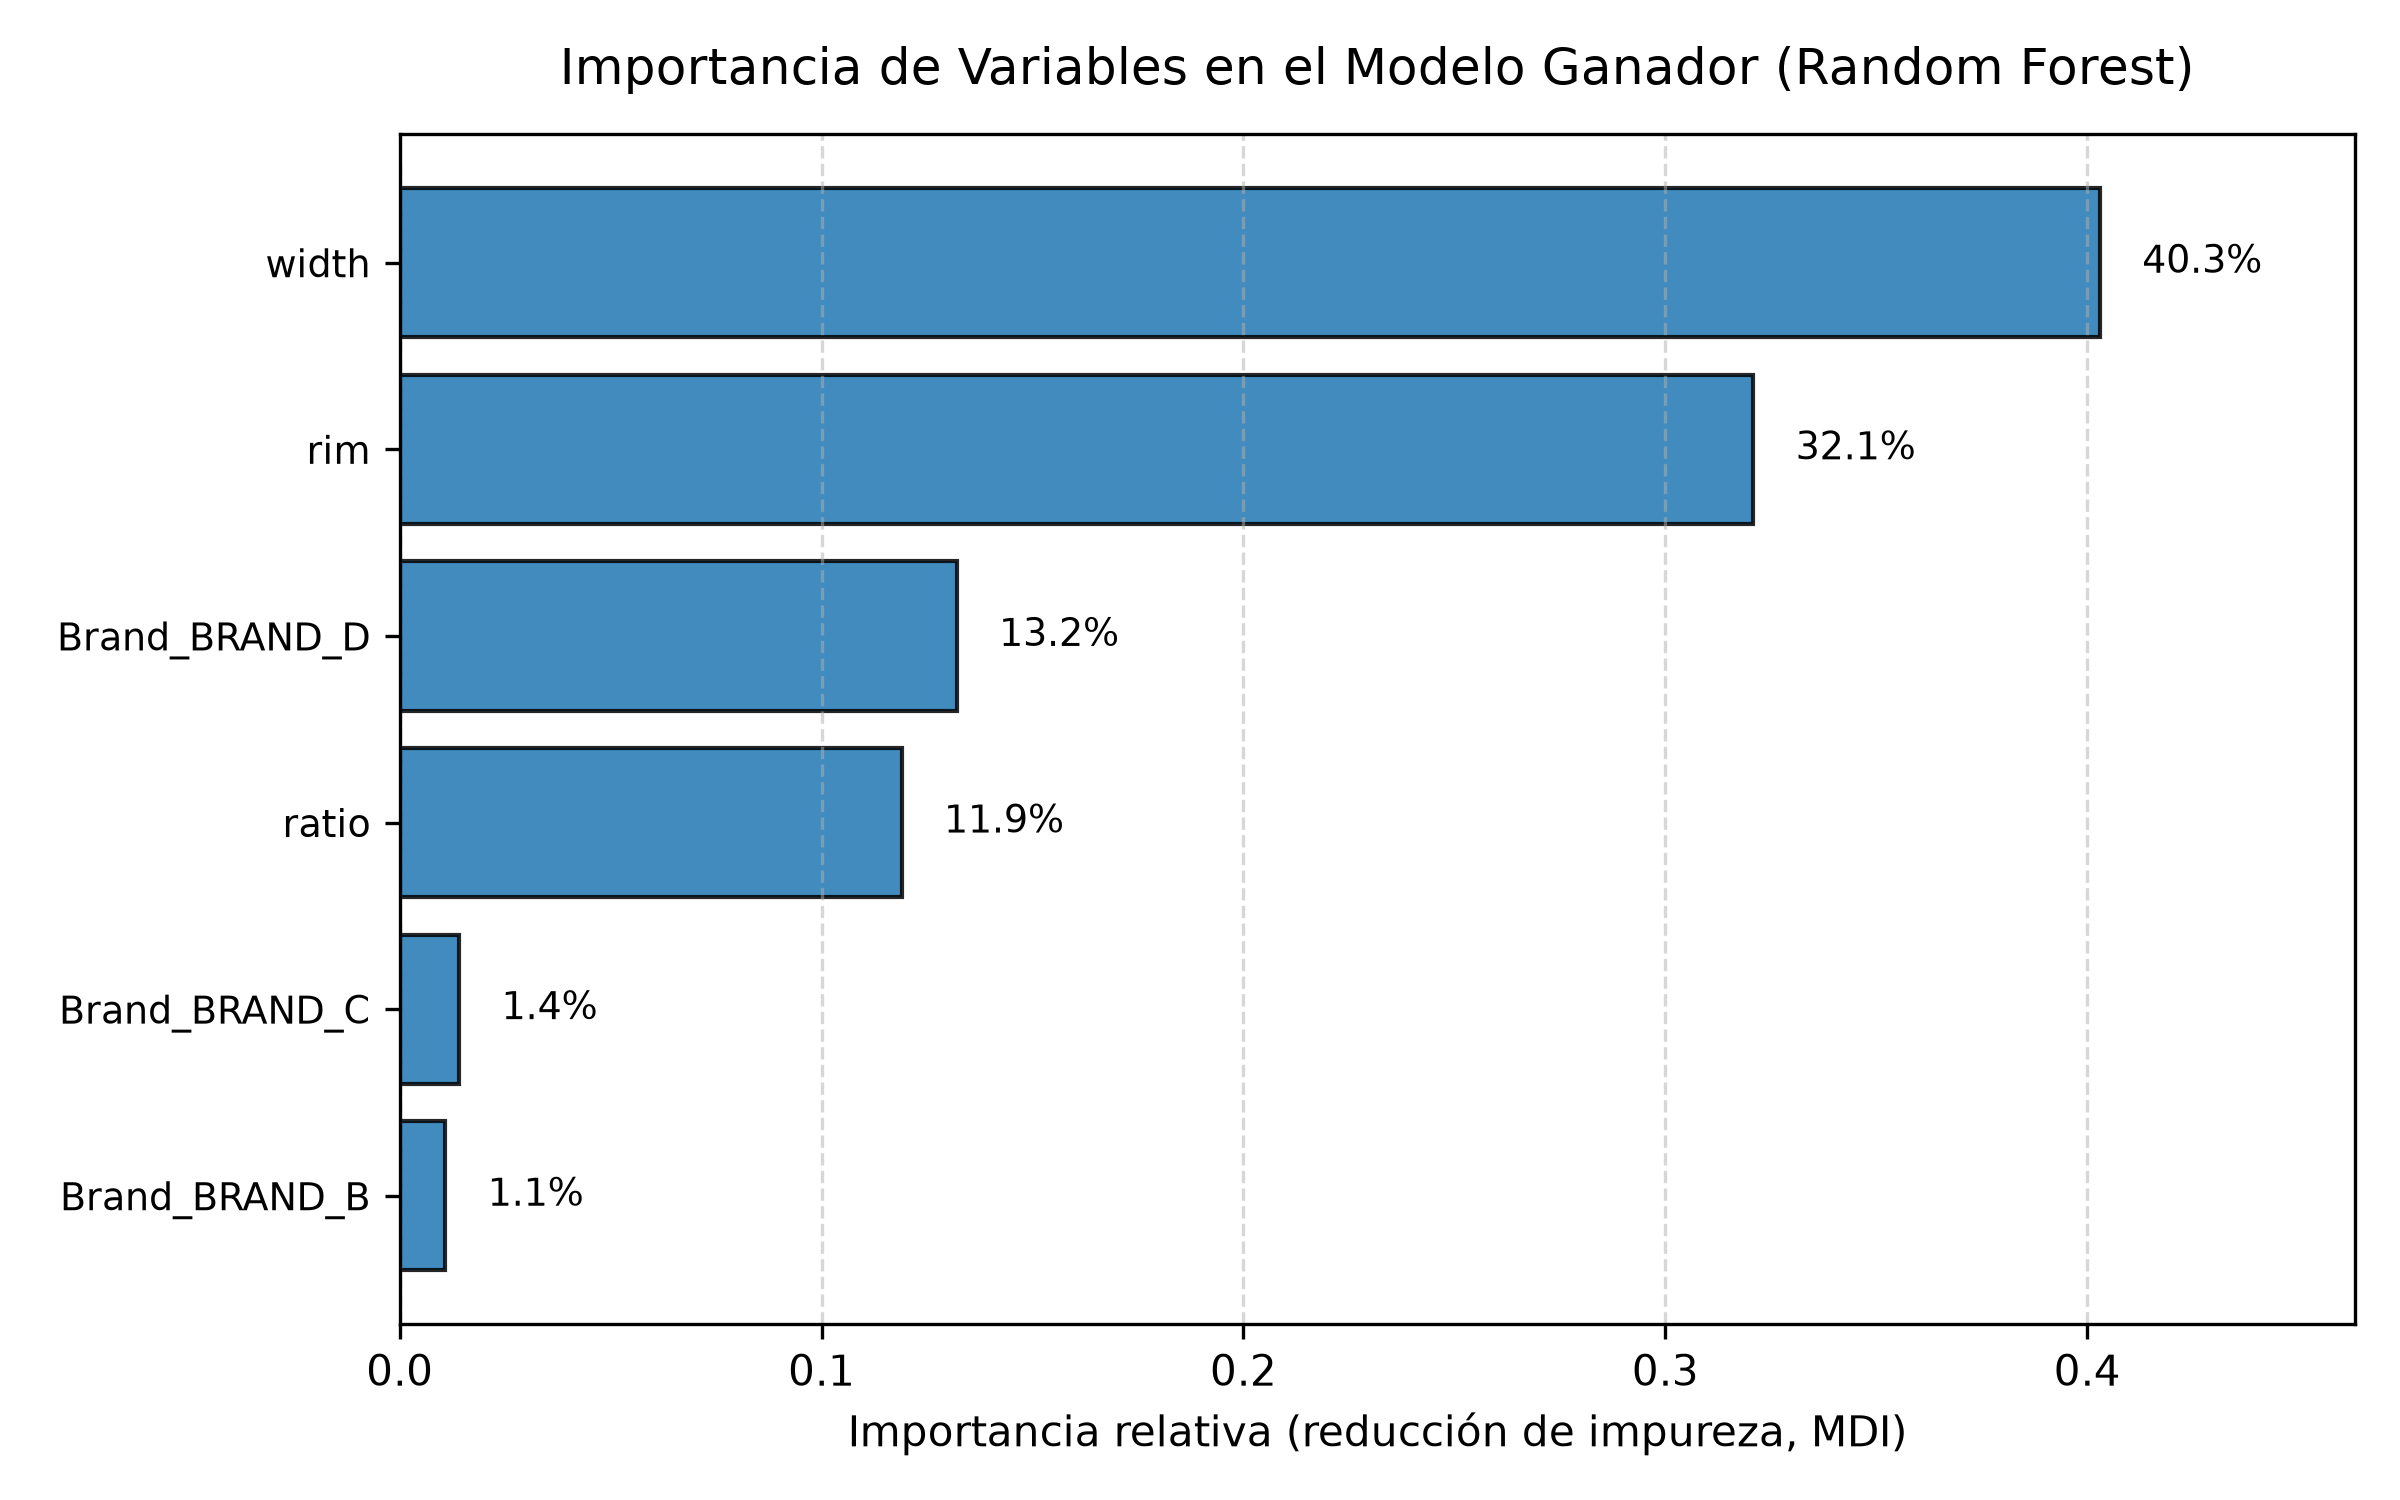

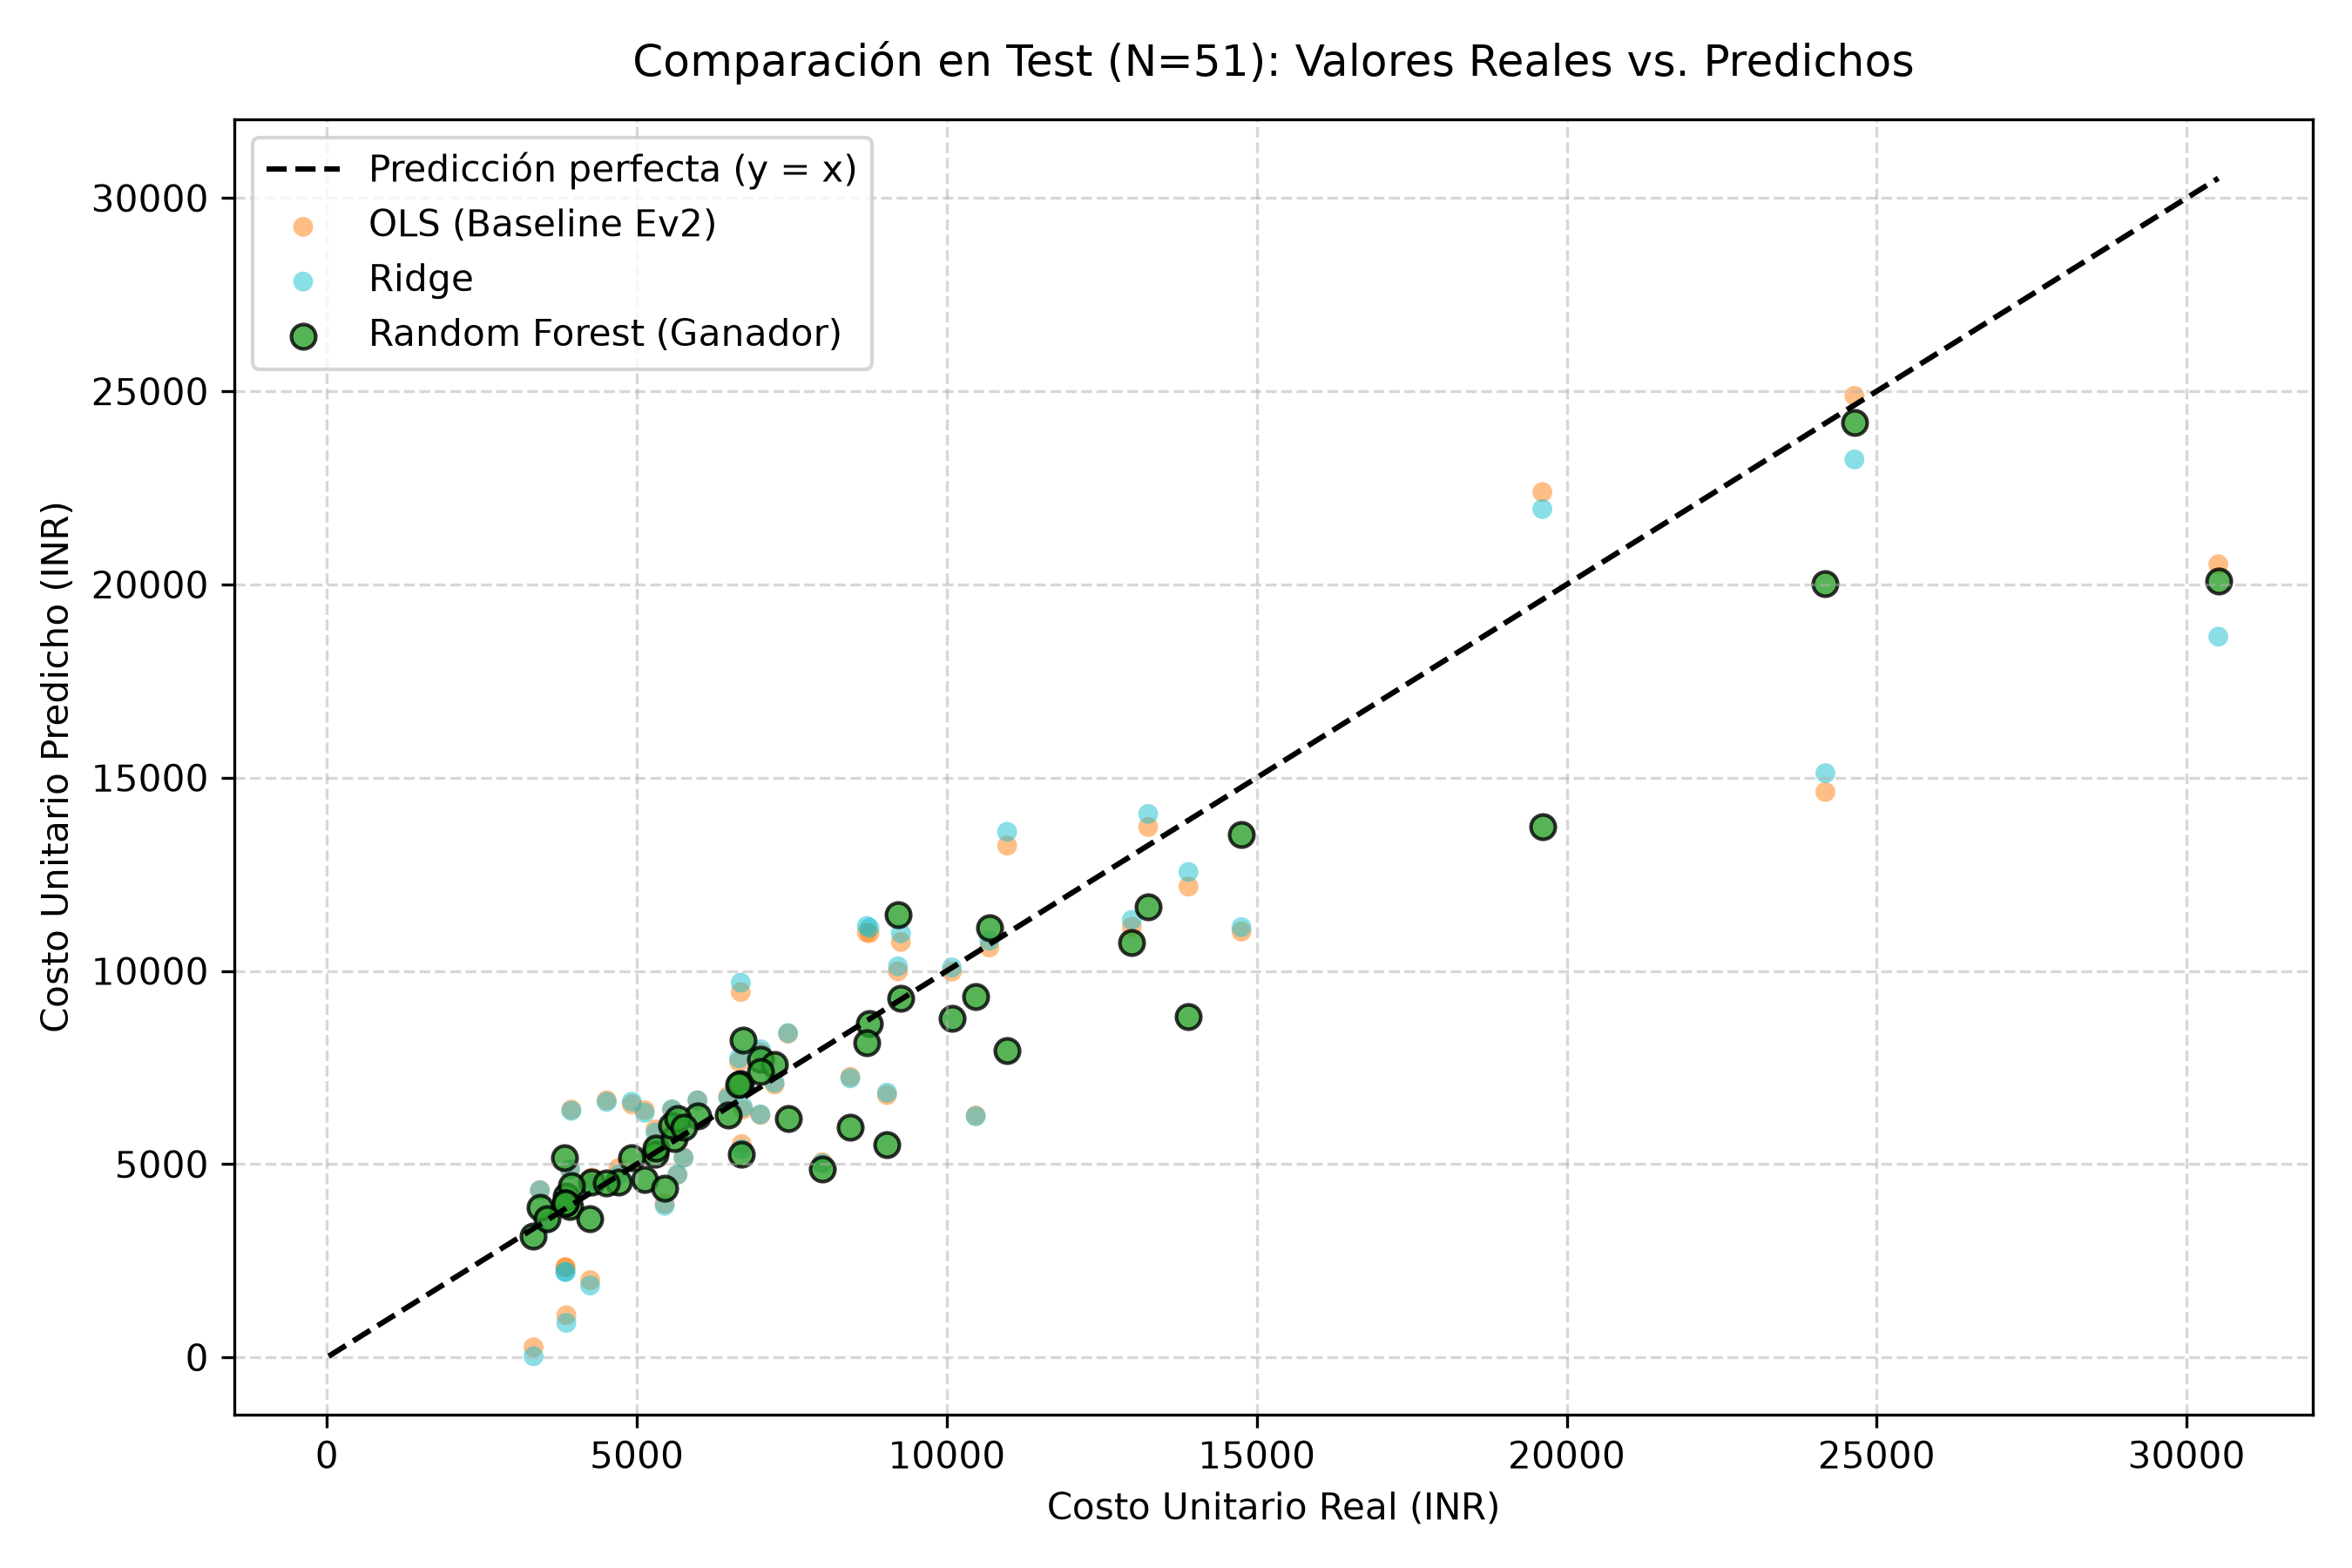

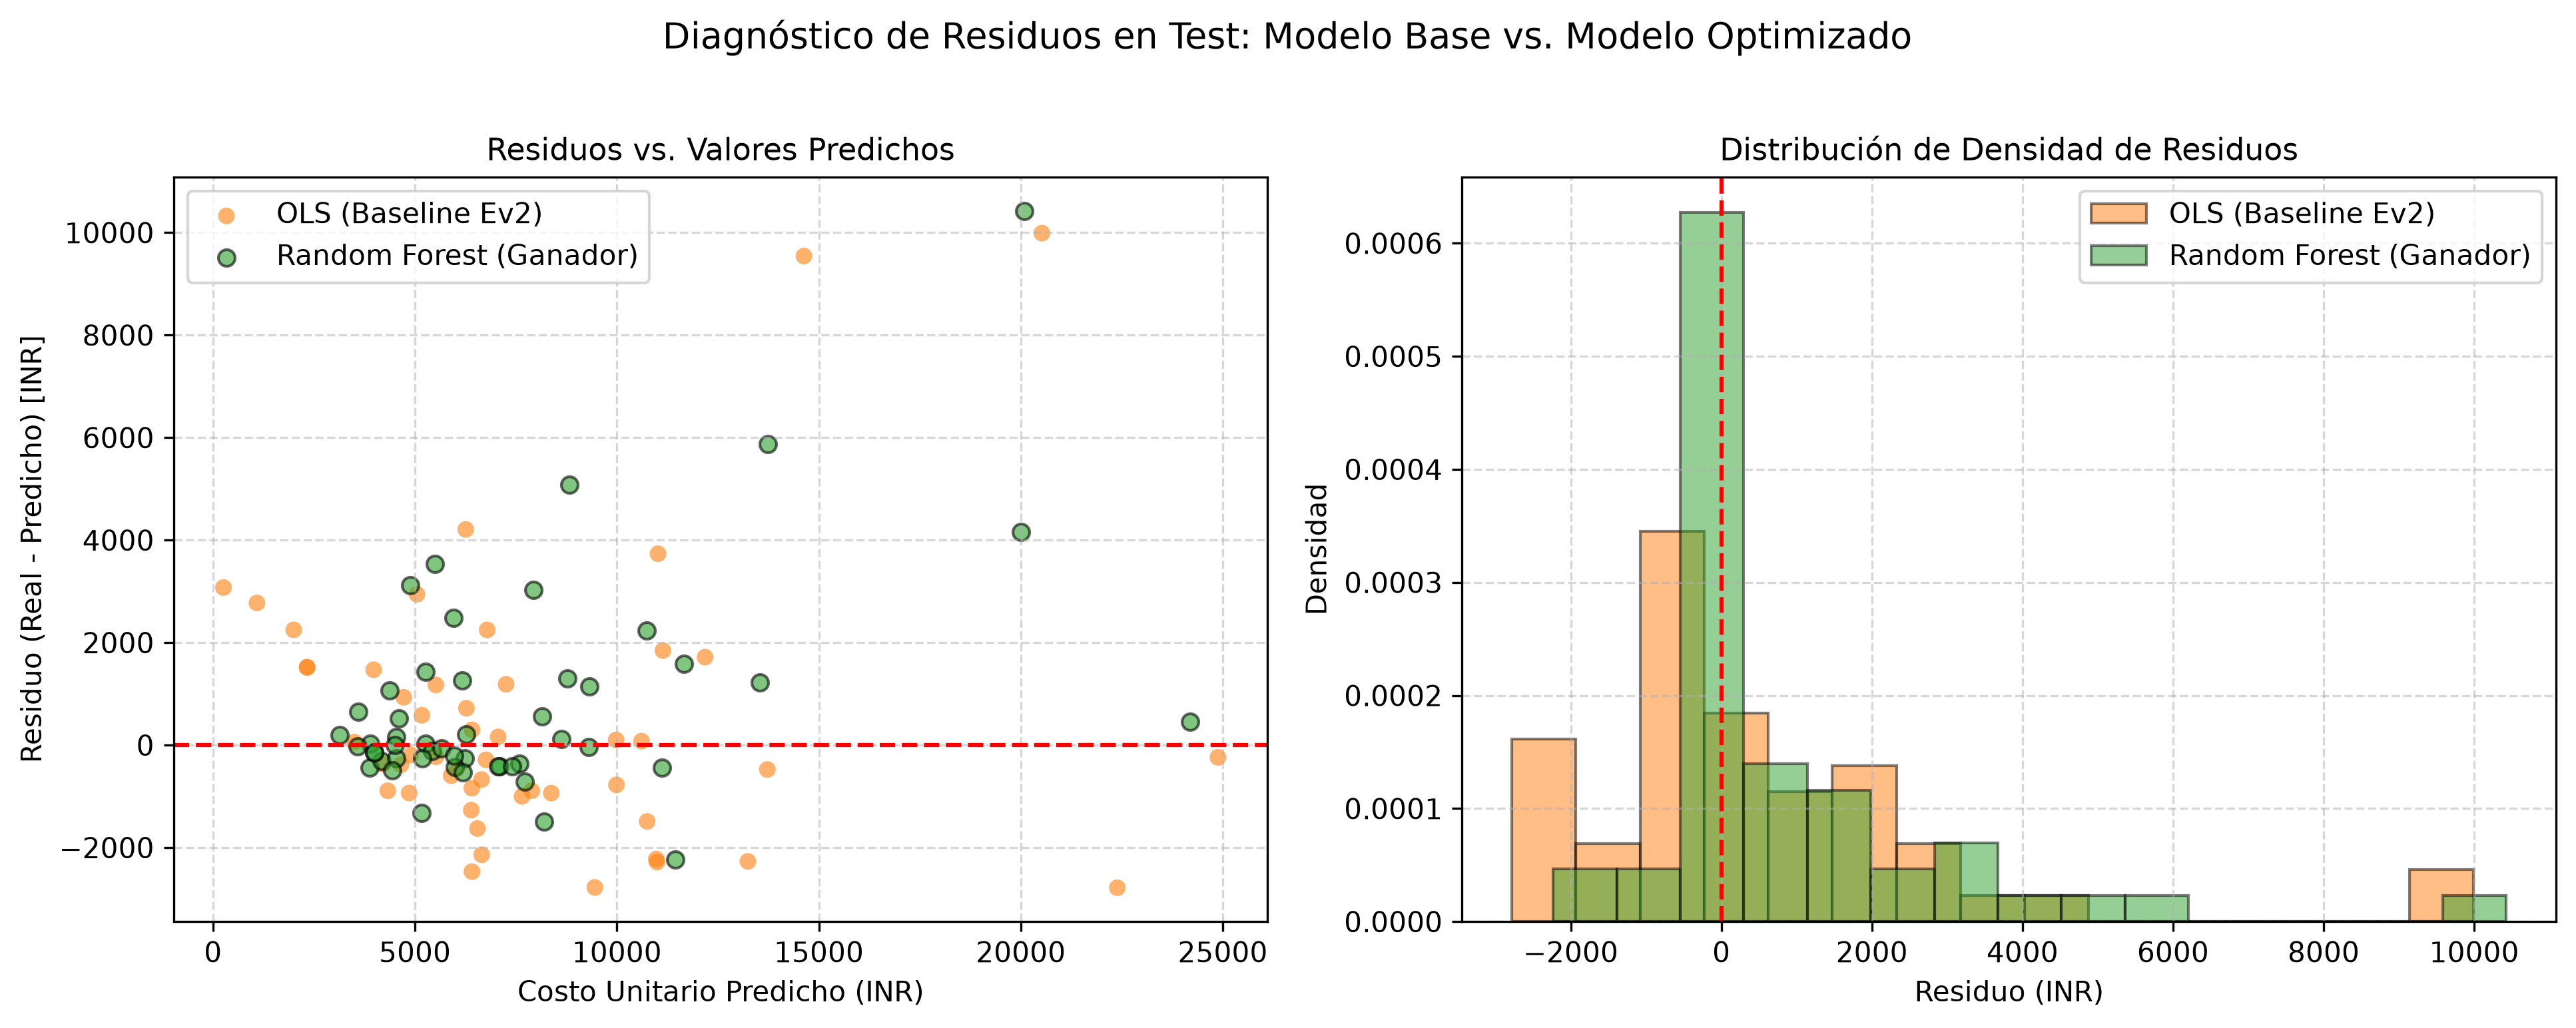

In [9]:
from IPython.display import Image, display
for f in ['ev3_cv_comparacion_modelos.png', 'ev3_importancia_variables.png', 'ev3_reales_vs_predichos.png', 'ev3_diagnostico_residuos.png']:
    display(Image(filename=os.path.join(fig_dir, f), width=700))

**AnÃ¡lisis de las figuras diagnÃ³sticas:**
* **Boxplot de CV (Figura 1):** Muestra visualmente la compresiÃ³n del error en Random Forest y su mayor estabilidad entre particiones.
* **Importancia de variables (Figura 2):** El ancho de secciÃ³n (`width`, $40{,}3\%$) y el diÃ¡metro del rin (`rim`, $32{,}1\%$) explican conjuntamente el $72{,}4\%$ de la impureza, seguidos por la marca pesada `Brand_BRAND_D` ($13{,}2\%$) y el perfil `ratio` ($11{,}9\%$). Las marcas estÃ¡ndar y econÃ³micas (`BRAND_B` y `BRAND_C`) aportan menos del $2{,}5\%$ combinado.
* **Reales vs Predichos (Figura 3):** Las estimaciones de Random Forest se alinean con mayor fidelidad a la recta ideal $y=x$, mitigando la subestimaciÃ³n en neumÃ¡ticos costosos.
* **DiagnÃ³stico de residuos (Figura 4):** Se atenÃºa la heterocedasticidad en la cola superior y la densidad de residuos muestra una campana mÃ¡s angosta centrada en cero.

## 9. Puesta en producciÃ³n (opcional)
Exportamos el pipeline completo (preprocesamiento + Random Forest), asÃ­ recibe datos crudos e imputa `ratio` si falta.

In [10]:
model_path = os.path.join('..', 'models', 'best_model.joblib')
save_model_artifact(rf_best, model_path)
from src.predict import predict_single_tire
casos = [(14.0, 175.0, 65.0, 'BRAND_C'), (17.0, 225.0, 50.0, 'BRAND_A'), (22.5, 279.4, None, 'BRAND_D')]
for rim, width, ratio, brand in casos:
    p = predict_single_tire(rim, width, ratio, brand, model_path=model_path)
    print(f"rim={rim} width={width} ratio={ratio} {brand} -> {p:,.2f} INR")

rim=14.0 width=175.0 ratio=65.0 BRAND_C -> 3,870.80 INR


rim=17.0 width=225.0 ratio=50.0 BRAND_A -> 7,123.11 INR


rim=22.5 width=279.4 ratio=None BRAND_D -> 24,186.33 INR


El modelo Random Forest fue exportado en `models/best_model.joblib`. Al incluir el `ColumnTransformer` en el pipeline, admite datos crudos y gestiona automÃ¡ticamente la imputaciÃ³n de `ratio` si estÃ¡ ausente. Las cotizaciones reales obtenidas reflejan de forma coherente la escala de valor:
* NeumÃ¡tico econÃ³mico rodado 14 (`BRAND_C`): **$3.870{,}80$ INR**.
* NeumÃ¡tico turismo rodado 17 (`BRAND_A`): **$7.123{,}11$ INR**.
* NeumÃ¡tico pesado rodado 22.5 (`BRAND_D`, perfil imputado por mediana): **$24.186{,}33$ INR**.

## 10. Conclusiones y Respuestas a la Consigna
1. **OptimizaciÃ³n con Grid Search y CV:** Se estructurÃ³ un pipeline hermÃ©tico con `ColumnTransformer` y validaciÃ³n cruzada 5-Fold, evaluando de forma exhaustiva hiperparÃ¡metros de penalizaciÃ³n (Ridge $\alpha$) y de ensamble (Random Forest: estimadores, profundidad, hojas mÃ­nimas y submuestreo de variables).
2. **ComparaciÃ³n de Algoritmos:** Se contrastaron 3 modelos (Lineal OLS, Ridge regularizado y Random Forest).
3. **Mejora Significativa:** Se comprobÃ³ de forma rigurosa. En validaciÃ³n cruzada pareada, Random Forest superÃ³ al baseline en el **$100\%$ de los folds** (reducciÃ³n media de $1.208$ INR), y en Test redujo el MAE en un $25{,}94\%$ y el RMSE en un $12{,}54\%$, llevando el $R^2$ a $0{,}8446$.
4. **Puesta en ProducciÃ³n:** Se serializÃ³ el pipeline ganador en `models/best_model.joblib` y se probÃ³ satisfactoriamente con la herramienta CLI `src/predict.py`.